# BlueShift: Mindanao Offshore Ocean Zones

Generate 15 km offshore zones for coastal provinces, remove land, assign each ocean cell to its nearest provincial coastline, and export the results.

## 1. Import libraries

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from pyproj import CRS

from shapely.geometry import (
    LineString, MultiLineString, Polygon, MultiPolygon, GeometryCollection, shape
)
from shapely.ops import unary_union
from shapely import make_valid

from scipy.spatial import cKDTree
from rasterio.features import rasterize, shapes
from rasterio.transform import from_origin

import warnings
warnings.filterwarnings("ignore")

## 2. Configure the project

In [2]:
DATA_DIR = Path("../data")
RAW_DIR = DATA_DIR / "raw"
OUTPUT_DIR = DATA_DIR / "processed"
ZONES_DIR = OUTPUT_DIR / "ocean_zones"

ADMIN_FILE = RAW_DIR / "phl_admin_boundaries" / "phl_admin2.shp"

PROVINCE_COLUMN = "adm2_name"

BUFFER_DISTANCE = 15_000       # 15 km
COAST_SAMPLE_DISTANCE = 100    # 100 m
GRID_RESOLUTION = 250          # 250 m

# Local metric CRS for Mindanao and nearby island groups
PROJECT_CRS = CRS.from_proj4(
    "+proj=aeqd +lat_0=7.5 +lon_0=125 "
    "+datum=WGS84 +units=m +no_defs"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ZONES_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration ready.")

Configuration ready.


## 3. Load and inspect boundaries

In [3]:
admin = gpd.read_file(ADMIN_FILE)

print("Records:", len(admin))
print("Columns:", admin.columns.tolist())
print("Source CRS:", admin.crs)

if PROVINCE_COLUMN not in admin.columns:
    raise ValueError(f"Missing province column: {PROVINCE_COLUMN}")

admin[[PROVINCE_COLUMN]].head()

Records: 88
Columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']
Source CRS: EPSG:4326


,adm2_name
0,Ilocos Norte
1,Ilocos Sur
2,La Union
3,Pangasinan
4,Batanes


## 4. Select the Mindanao study area

In [4]:
MINDANAO_PROVINCES = [
    "Agusan del Norte", "Agusan del Sur",
    "Basilan", "Bukidnon", "Camiguin", "Cotabato",
    "Davao de Oro", "Davao del Norte", "Davao del Sur",
    "Davao Occidental", "Davao Oriental", "Dinagat Islands",
    "Lanao del Norte", "Lanao del Sur",
    "Maguindanao del Norte", "Maguindanao del Sur",
    "Misamis Occidental", "Misamis Oriental",
    "Sarangani", "South Cotabato", "Sultan Kudarat",
    "Surigao del Norte", "Surigao del Sur",
    "Tawi-Tawi", "Zamboanga del Norte",
    "Zamboanga del Sur", "Zamboanga Sibugay", "Sulu"
]

# Normalize source names
admin[PROVINCE_COLUMN] = admin[PROVINCE_COLUMN].replace({
    "Cotabato (North Cotabato)": "Cotabato",
    "Davao de Oro (Compostela Valley)": "Davao de Oro"
})

admin["province_normalized"] = (
    admin[PROVINCE_COLUMN].astype(str).str.strip().str.casefold()
)
mindanao_names = {name.casefold() for name in MINDANAO_PROVINCES}

missing = mindanao_names - set(admin["province_normalized"])
print("Unmatched names:", sorted(missing))

Unmatched names: []


## 5. Reproject and clean geometries
Simplify once, before creating the Mindanao subset. This keeps the province boundaries and national land mask consistent.

In [5]:
admin = admin.to_crs(PROJECT_CRS)

admin = admin[
    admin.geometry.notna() & ~admin.geometry.is_empty
].copy()

admin["geometry"] = admin.geometry.apply(make_valid)

# Reduce vertex count while retaining the general coastline shape
admin["geometry"] = admin.geometry.simplify(
    tolerance=100,
    preserve_topology=True
)

admin["geometry"] = admin.geometry.apply(make_valid)

mindanao = admin[
    admin["province_normalized"].isin(mindanao_names)
].copy()

print("Philippine province polygons:", len(admin))
print("Mindanao study polygons:", len(mindanao))
print("Mindanao provinces found:", mindanao[PROVINCE_COLUMN].nunique())

Philippine province polygons: 88
Mindanao study polygons: 28
Mindanao provinces found: 28


## 6. Plot the study area

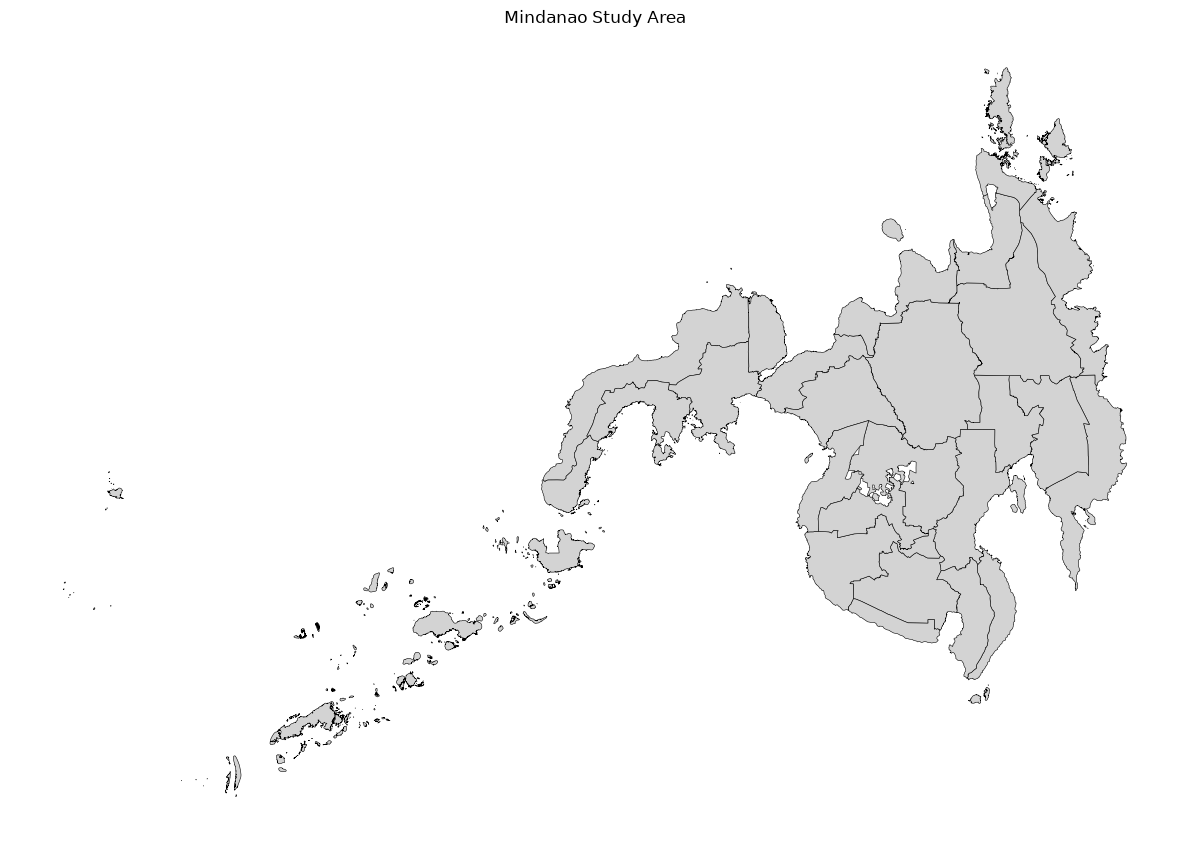

In [6]:
fig, ax = plt.subplots(figsize=(12, 12))
mindanao.plot(ax=ax, color="lightgray", edgecolor="black", linewidth=0.4)
ax.set_title("Mindanao Study Area")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 7. Build the national land mask
Use all Philippine province polygons so nearby islands outside the Mindanao province list are still treated as land.

In [7]:
national_land = admin.geometry.union_all()
national_land = make_valid(national_land)

# Keep only polygon exterior rings. This excludes inland lake boundaries.
def polygon_exterior_lines(geometry):
    lines = []

    if geometry is None or geometry.is_empty:
        return lines

    if geometry.geom_type == "Polygon":
        lines.append(LineString(geometry.exterior.coords))

    elif geometry.geom_type == "MultiPolygon":
        for polygon in geometry.geoms:
            lines.append(LineString(polygon.exterior.coords))

    elif hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            lines.extend(polygon_exterior_lines(part))

    return lines

national_coastline = unary_union(
    polygon_exterior_lines(national_land)
)

print("National land mask and external coastline ready.")

National land mask and external coastline ready.


## 8. Extract each province's actual coastline
Intersect each province boundary with the exterior boundary of the dissolved national landmass. Because both come from the same cleaned geometries, shared provincial borders are excluded.

In [8]:
def extract_lines(geometry):
    if geometry is None or geometry.is_empty:
        return []

    if geometry.geom_type in ("LineString", "LinearRing"):
        return [LineString(geometry.coords)]

    lines = []
    if hasattr(geometry, "geoms"):
        for part in geometry.geoms:
            lines.extend(extract_lines(part))

    return lines


coastal_records = []

for _, province in mindanao.iterrows():
    province_name = province[PROVINCE_COLUMN]

    coastline = province.geometry.boundary.intersection(
        national_coastline
    )

    line_parts = extract_lines(coastline)

    if not line_parts:
        continue

    coastline = unary_union(line_parts)

    coastal_records.append({
        "province": province_name,
        "geometry": coastline
    })

coastal = gpd.GeoDataFrame(
    coastal_records,
    geometry="geometry",
    crs=PROJECT_CRS
)

print("Coastal provinces:", len(coastal))
print(coastal.geom_type.value_counts())

Coastal provinces: 24
MultiLineString    24
Name: count, dtype: int64


## 9. Inspect coastlines

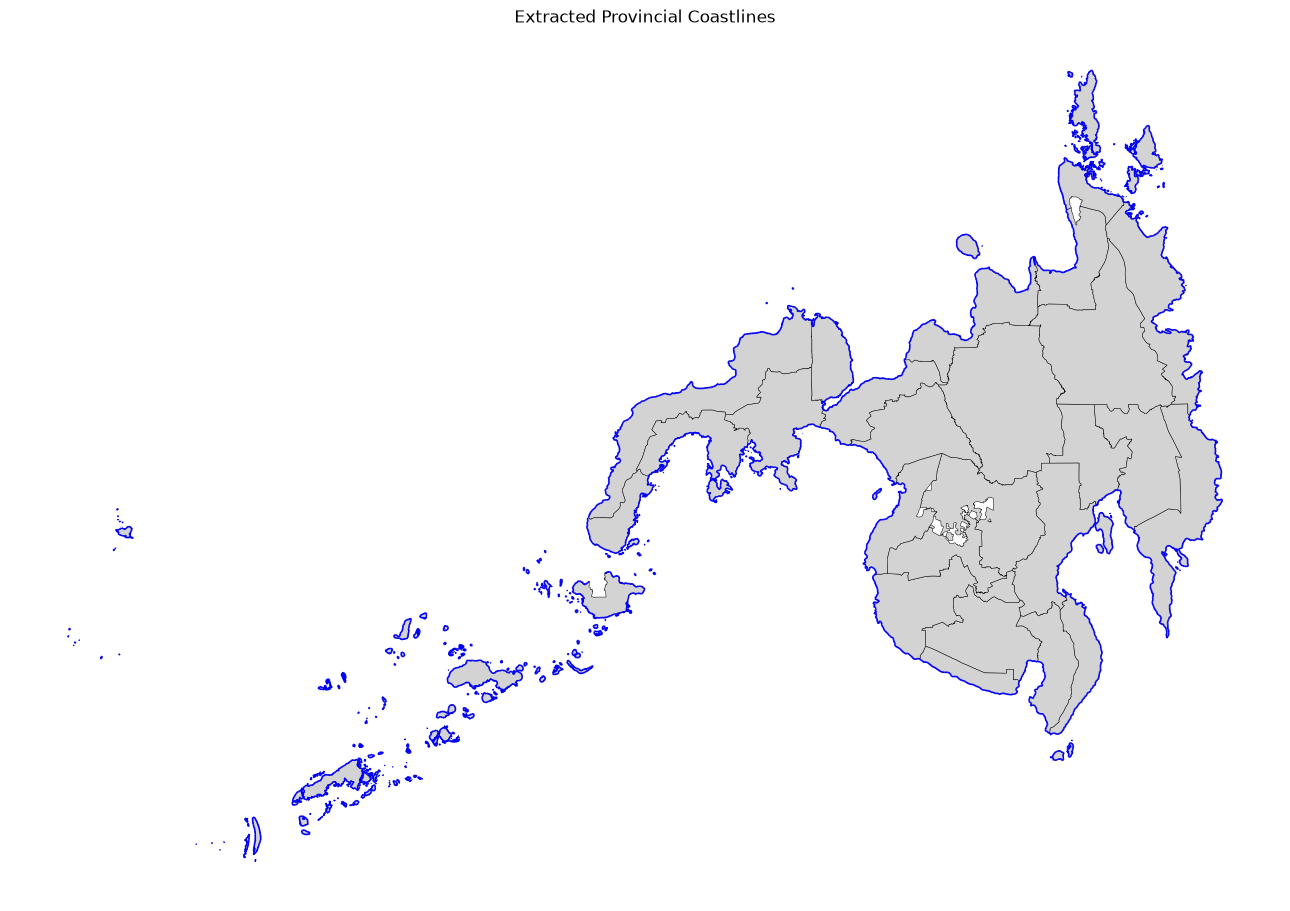

,province,coastline_km
21,Sulu,1537.179309
22,Tawi-Tawi,1285.315790
16,Surigao del Norte,932.199808
1,Zamboanga del Sur,661.944896
17,Surigao del Sur,568.405605
19,Basilan,528.983659
2,Zamboanga Sibugay,509.376332
9,Davao Oriental,506.320135
0,Zamboanga del Norte,448.343348
18,Dinagat Islands,434.182236


In [9]:
fig, ax = plt.subplots(figsize=(13, 13))
mindanao.plot(ax=ax, color="lightgray", edgecolor="black", linewidth=0.35)
coastal.plot(ax=ax, color="blue", linewidth=1.2)
ax.set_title("Extracted Provincial Coastlines")
ax.set_axis_off()
plt.tight_layout()
plt.show()

coastal_lengths = coastal[["province"]].copy()
coastal_lengths["coastline_km"] = coastal.geometry.length / 1000
coastal_lengths.sort_values("coastline_km", ascending=False)

## 10. Create a spatial index and land lookup

In [10]:
land_sindex = admin.sindex

def get_nearby_land(search_geometry):
    indices = land_sindex.query(
        search_geometry,
        predicate="intersects"
    )

    if len(indices) == 0:
        return None

    nearby = admin.geometry.iloc[indices]

    # Clip before dissolving to reduce geometry size
    clipped = nearby.intersection(search_geometry)
    clipped = clipped[~clipped.is_empty]

    if len(clipped) == 0:
        return None

    return clipped.union_all()

print("Land spatial index ready.")

Land spatial index ready.


## 11. Generate 15 km offshore buffers
Buffer the actual coastline, then subtract all nearby land.

In [11]:
ocean_geometries = []

for _, province in coastal.iterrows():
    name = province["province"]
    print("Processing:", name)

    coastline_buffer = province.geometry.buffer(
        BUFFER_DISTANCE,
        quad_segs=8
    )

    nearby_land = get_nearby_land(coastline_buffer)

    if nearby_land is not None:
        ocean_geometry = coastline_buffer.difference(nearby_land)
    else:
        ocean_geometry = coastline_buffer

    if not ocean_geometry.is_valid:
        ocean_geometry = make_valid(ocean_geometry)

    ocean_geometries.append(ocean_geometry)

coastal["ocean_buffer"] = ocean_geometries
print("Offshore buffers generated.")

Processing: Zamboanga del Norte
Processing: Zamboanga del Sur
Processing: Zamboanga Sibugay
Processing: Camiguin
Processing: Lanao del Norte
Processing: Misamis Occidental
Processing: Misamis Oriental
Processing: Davao del Norte
Processing: Davao del Sur
Processing: Davao Oriental
Processing: Davao de Oro
Processing: Davao Occidental
Processing: South Cotabato
Processing: Sultan Kudarat
Processing: Sarangani
Processing: Agusan del Norte
Processing: Surigao del Norte
Processing: Surigao del Sur
Processing: Dinagat Islands
Processing: Basilan
Processing: Lanao del Sur
Processing: Sulu
Processing: Tawi-Tawi
Processing: Maguindanao del Norte
Offshore buffers generated.


## 12. Inspect initial buffers

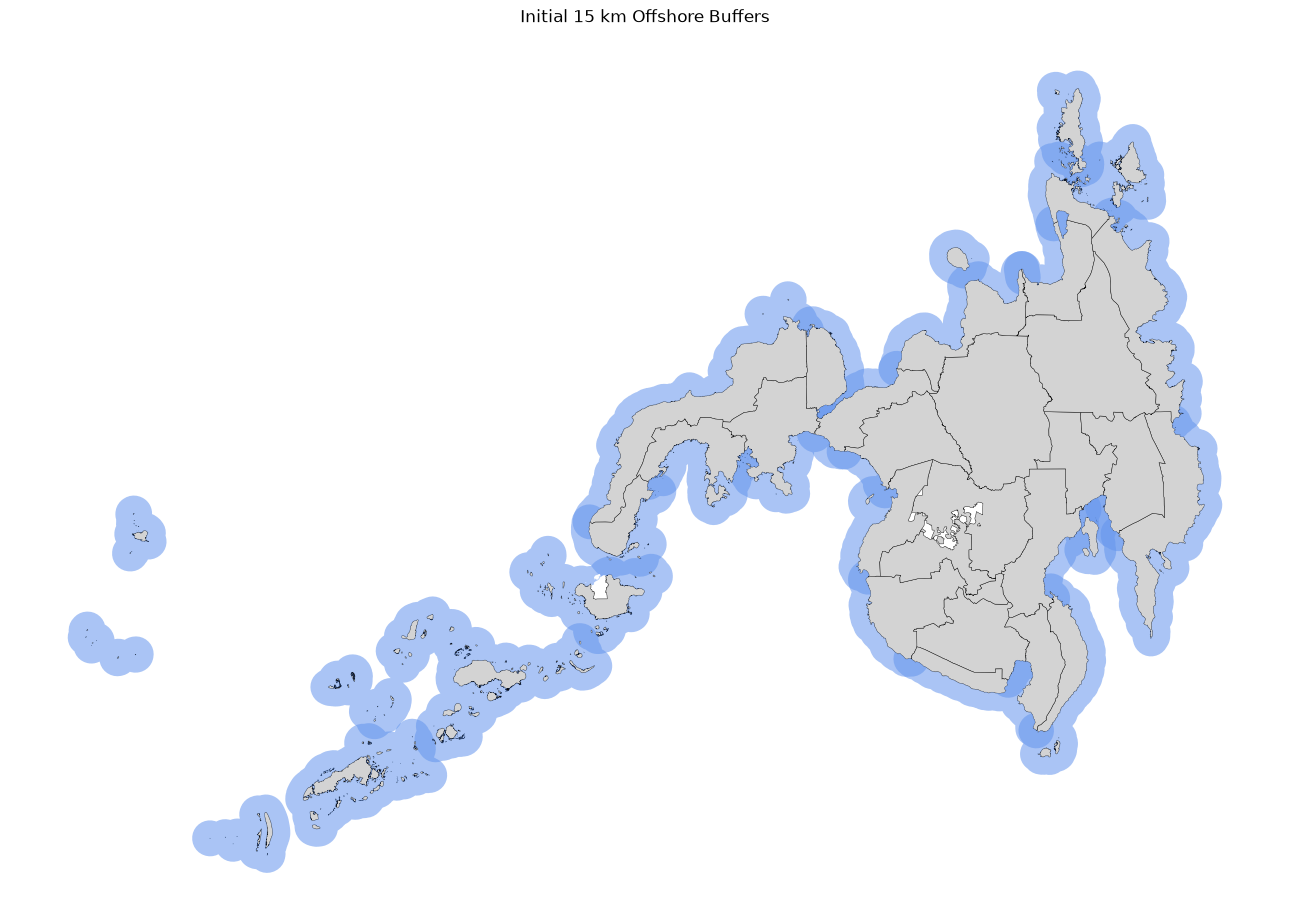

In [12]:
fig, ax = plt.subplots(figsize=(13, 13))
mindanao.plot(ax=ax, color="lightgray", edgecolor="black", linewidth=0.3)
gpd.GeoSeries(coastal["ocean_buffer"], crs=PROJECT_CRS).plot(
    ax=ax, color="cornflowerblue", alpha=0.55
)
ax.set_title("Initial 15 km Offshore Buffers")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 13. Sample the coastlines
Sample points every 100 m. Each point stores its province ID.

In [13]:
province_id_map = {
    i: name
    for i, name in enumerate(coastal["province"].tolist(), start=1)
}

sample_points = []
sample_province_ids = []

for province_id, (_, province) in enumerate(coastal.iterrows(), start=1):
    for line in extract_lines(province.geometry):
        distances = np.arange(0, line.length, COAST_SAMPLE_DISTANCE)
        distances = np.append(distances, line.length)

        for distance in distances:
            point = line.interpolate(distance)
            sample_points.append((point.x, point.y))
            sample_province_ids.append(province_id)

sample_points = np.asarray(sample_points, dtype=np.float64)
sample_province_ids = np.asarray(sample_province_ids, dtype=np.int16)

if len(sample_points) == 0:
    raise ValueError("No coastline samples were generated.")

coast_tree = cKDTree(sample_points)

print("Coastline samples:", len(sample_points))

Coastline samples: 126903


## 14. Combine candidate ocean areas

In [14]:
candidate_ocean = unary_union(coastal["ocean_buffer"].tolist())
candidate_ocean = make_valid(candidate_ocean)

print("Candidate ocean area (km²):", round(candidate_ocean.area / 1e6, 2))

Candidate ocean area (km²): 87065.9


## 15. Create the ocean grid
A 250 m grid is used to assign each ocean location to its nearest coastline.

In [15]:
minx, miny, maxx, maxy = candidate_ocean.bounds
resolution = GRID_RESOLUTION

width = int(np.ceil((maxx - minx) / resolution))
height = int(np.ceil((maxy - miny) / resolution))

transform = from_origin(minx, maxy, resolution, resolution)

print("Grid:", width, "x", height)
print("Total grid cells:", width * height)

Grid: 3900 x 2710
Total grid cells: 10569000


In [16]:
ocean_mask = rasterize(
    [(candidate_ocean, 1)],
    out_shape=(height, width),
    transform=transform,
    fill=0,
    dtype="uint8",
    all_touched=False
)

rows, cols = np.where(ocean_mask == 1)

print("Ocean cells:", len(rows))

Ocean cells: 1393139


## 16. Assign cells to the nearest coastline

In [17]:
province_raster = np.zeros((height, width), dtype=np.int16)

CHUNK_SIZE = 250_000

for start in range(0, len(rows), CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, len(rows))

    chunk_rows = rows[start:end]
    chunk_cols = cols[start:end]

    x = minx + (chunk_cols + 0.5) * resolution
    y = maxy - (chunk_rows + 0.5) * resolution
    coordinates = np.column_stack((x, y))

    _, nearest_indices = coast_tree.query(
        coordinates,
        k=1,
        workers=-1
    )

    province_raster[chunk_rows, chunk_cols] = (
        sample_province_ids[nearest_indices]
    )

    print(f"Assigned {end:,} / {len(rows):,} cells")

print("Nearest-coast assignment complete.")

Assigned 250,000 / 1,393,139 cells
Assigned 500,000 / 1,393,139 cells
Assigned 750,000 / 1,393,139 cells
Assigned 1,000,000 / 1,393,139 cells
Assigned 1,250,000 / 1,393,139 cells
Assigned 1,393,139 / 1,393,139 cells
Nearest-coast assignment complete.


## 17. Summarize assigned ocean area

In [18]:
counts = pd.Series(
    province_raster[province_raster > 0]
).value_counts().sort_index()

assignment_summary = pd.DataFrame({
    "province_id": counts.index,
    "province": [province_id_map[i] for i in counts.index],
    "grid_cells": counts.values
})

assignment_summary["area_km2"] = (
    assignment_summary["grid_cells"] * resolution**2 / 1e6
)

assignment_summary.sort_values("area_km2", ascending=False)

,province_id,province,grid_cells,area_km2
22,23,Tawi-Tawi,242823,15176.4375
21,22,Sulu,241925,15120.3125
19,20,Basilan,96008,6000.5000
0,1,Zamboanga del Norte,92403,5775.1875
9,10,Davao Oriental,85481,5342.5625
16,17,Surigao del Norte,79053,4940.8125
1,2,Zamboanga del Sur,75880,4742.5000
17,18,Surigao del Sur,67023,4188.9375
11,12,Davao Occidental,59485,3717.8125
6,7,Misamis Oriental,47002,2937.6250


## 18. Convert assignments to polygons

In [19]:
province_polygons = {province_id: [] for province_id in province_id_map}

for geom, value in shapes(
    province_raster,
    mask=(province_raster > 0),
    transform=transform,
    connectivity=4
):
    province_polygons[int(value)].append(shape(geom))

zone_records = []

for province_id, geometries in province_polygons.items():
    if not geometries:
        continue

    zone = unary_union(geometries)
    zone = zone.intersection(candidate_ocean)

    if not zone.is_valid:
        zone = make_valid(zone)

    if zone.is_empty:
        continue

    zone_records.append({
        "province_id": province_id,
        "province": province_id_map[province_id],
        "geometry": zone
    })

ocean_zones = gpd.GeoDataFrame(
    zone_records,
    geometry="geometry",
    crs=PROJECT_CRS
)

print("Exclusive zones:", len(ocean_zones))

Exclusive zones: 24


## 19. Validate the zones

In [20]:
# A. Check overlap
sum_area = ocean_zones.geometry.area.sum()
union_area = ocean_zones.geometry.union_all().area
overlap_area = sum_area - union_area

print("Overlap area (m²):", round(overlap_area, 6))

# B. Check land intersections
land_overlap = []

for _, zone in ocean_zones.iterrows():
    nearby_land = get_nearby_land(zone.geometry)
    overlap = 0 if nearby_land is None else zone.geometry.intersection(nearby_land).area

    land_overlap.append({
        "province": zone["province"],
        "land_overlap_m2": overlap
    })

land_check = pd.DataFrame(land_overlap)
print("Total land overlap (m²):", land_check["land_overlap_m2"].sum())

# C. Check coverage
print("Missing provinces:", set(coastal["province"]) - set(ocean_zones["province"]))

Overlap area (m²): -0.000565
Total land overlap (m²): 1.0278886189923202e-10
Missing provinces: set()


## 20. Visualize exclusive ocean zones

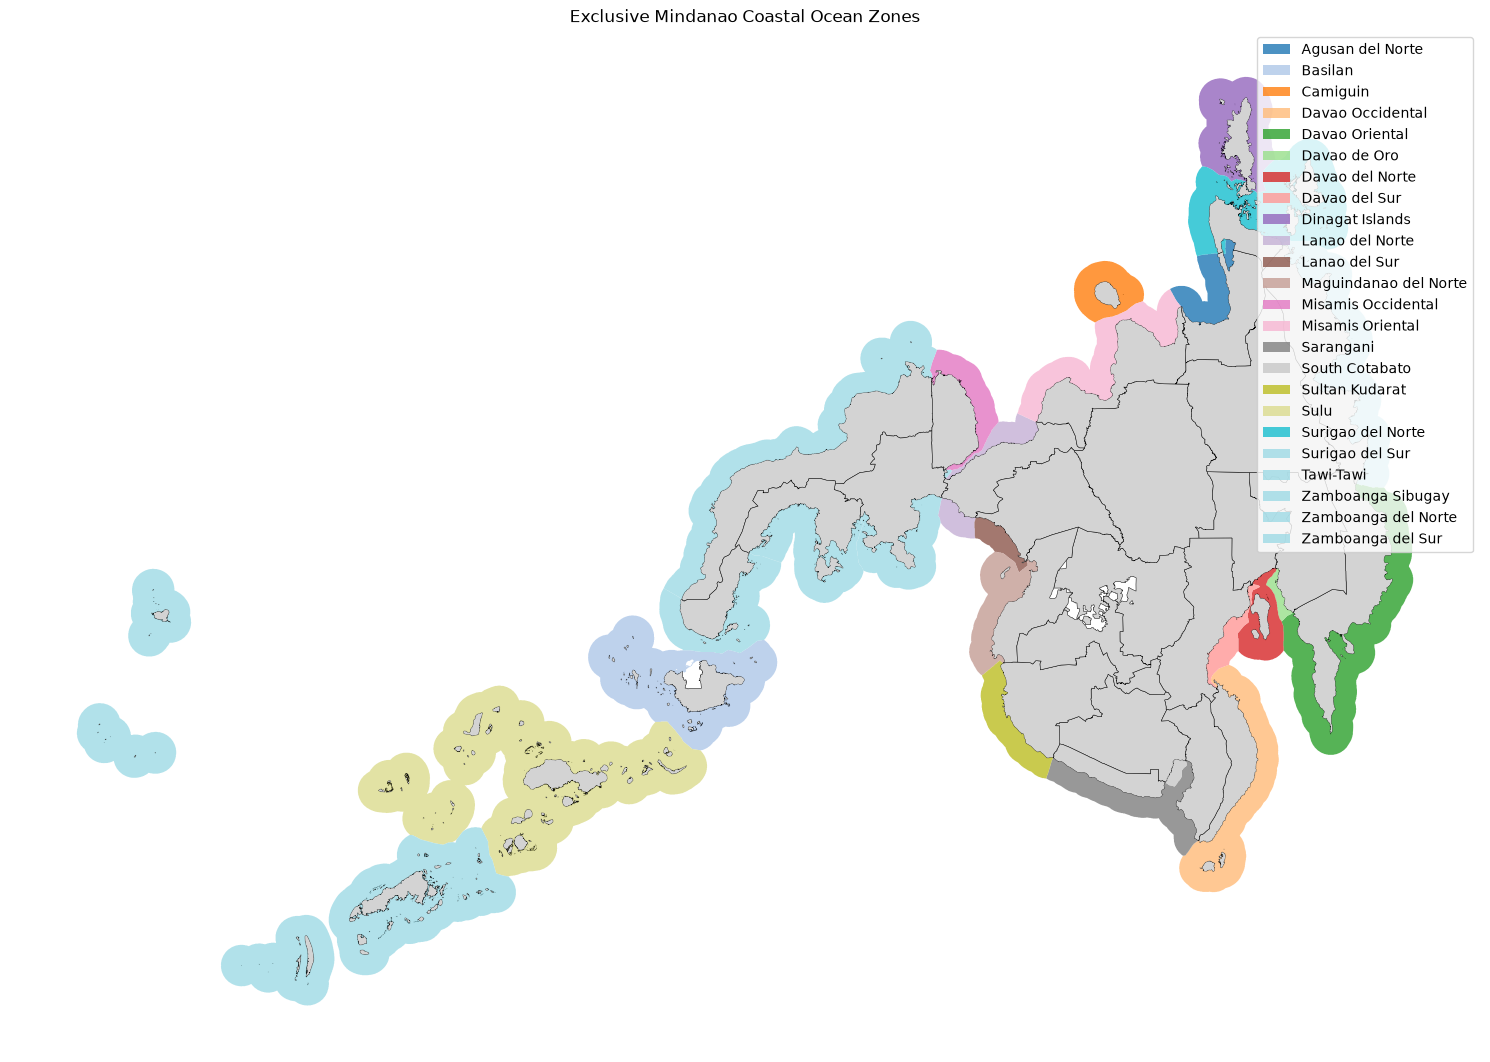

In [21]:
fig, ax = plt.subplots(figsize=(15, 15))

mindanao.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.35
)

ocean_zones.plot(
    ax=ax,
    column="province",
    categorical=True,
    legend=True,
    alpha=0.8,
    edgecolor="none"
)

ax.set_title("Exclusive Mindanao Coastal Ocean Zones")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 21. Export results
Exports use EPSG:4326 for compatibility with NASA and other geographic datasets.

In [22]:
final_zones = ocean_zones.to_crs("EPSG:4326")

geojson_path = ZONES_DIR / "mindanao_coastal_ocean_zones.geojson"
gpkg_path = ZONES_DIR / "mindanao_coastal_ocean_zones.gpkg"

final_zones.to_file(geojson_path, driver="GeoJSON")
final_zones.to_file(gpkg_path, driver="GPKG")

for _, row in final_zones.iterrows():
    filename = (
        row["province"].lower().replace(" ", "_") + ".geojson"
    )

    single = gpd.GeoDataFrame(
        [row],
        geometry="geometry",
        crs="EPSG:4326"
    )

    single.to_file(ZONES_DIR / filename, driver="GeoJSON")

print("Export complete:")
print(geojson_path)
print(gpkg_path)
print(ZONES_DIR)

Export complete:
..\data\processed\ocean_zones\mindanao_coastal_ocean_zones.geojson
..\data\processed\ocean_zones\mindanao_coastal_ocean_zones.gpkg
..\data\processed\ocean_zones


## Notes

- The 15 km distance is an analytical study boundary, not a verified fishing-ground boundary.
- The 250 m grid controls the precision of provincial ownership boundaries. It does not represent the resolution of NASA satellite products.
- Coastline extraction depends on the administrative boundary dataset having consistent, topologically aligned province polygons. Inspect the coastline map before generating buffers.
- The study-area list includes the Sulu Archipelago and nearby island provinces.